# LAB 04 — Phân loại văn bản

## 1. Giới thiệu

Mục tiêu: so sánh TF-IDF + Logistic Regression, Average Word2Vec + Logistic Regression, TF-IDF + Linear SVM (nếu đủ tài nguyên), unigram/bigram và ảnh hưởng của thứ tự từ trên cùng một cách chia dữ liệu, đồng thời ngăn rò rỉ dữ liệu.

## 2. Thư viện và khả năng tái lập

In [1]:
from pathlib import Path
import csv, hashlib, io, json, math, random, statistics, time, zipfile
import sys, importlib.metadata, unittest
from collections import Counter, defaultdict
ROOT = Path.cwd()
if not (ROOT / "imdb.zip").exists() and (ROOT / "Lab04" / "imdb.zip").exists(): ROOT = ROOT / "Lab04"
sys.path.insert(0, str(ROOT))
from preprocessing import normalize_text, tokenize_text, has_missing_text, document_length_statistics, validate_labels
SEED = 42
random.seed(SEED)
ROOT = Path.cwd()
if not (ROOT / "imdb.zip").exists() and (ROOT / "Lab04" / "imdb.zip").exists():
    ROOT = ROOT / "Lab04"
if not (ROOT / "imdb.zip").exists() and "__file__" in globals():
    ROOT = Path(__file__).resolve().parent
DATA_ZIP = ROOT / "imdb.zip"
RESULTS_PATH = ROOT / "results.csv"
CONFUSION_PATH = ROOT / "confusion_matrix.png"
EXPECTED_DEPS = ["numpy", "pandas", "matplotlib", "sklearn", "gensim"]
deps = {}
dependency_errors = {}
for name in EXPECTED_DEPS:
    try: deps[name] = __import__(name)
    except Exception as exc:
        deps[name] = None
        dependency_errors[name] = repr(exc)
missing_deps = [name for name, module in deps.items() if module is None]
print({"seed": SEED, "zip_exists": DATA_ZIP.exists(), "missing_dependencies": missing_deps})
if missing_deps: raise ImportError(f"Thiếu thư viện bắt buộc: {dependency_errors}")
versions={name:importlib.metadata.version(name) for name in ["numpy","pandas","matplotlib","scikit-learn","gensim","nbclient","ipykernel"]}
print("Phiên bản thư viện:",versions)
np=deps["numpy"]
np.random.seed(SEED)
suite=unittest.defaultTestLoader.discover(str(ROOT),pattern="test_lab04.py")
unit_result=unittest.TextTestRunner(verbosity=1).run(suite)
assert unit_result.wasSuccessful()
print("Tests đạt:",unit_result.testsRun)

.

.

.

.

.

...

.

.

.

----------------------------------------------------------------------
Ran 9 tests in 0.007s

OK


{'seed': 42, 'zip_exists': True, 'missing_dependencies': []}
Phiên bản thư viện: {'numpy': '2.5.4', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'gensim': '4.4.0', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}
Tests đạt: 9


## 3. Tải tập dữ liệu

In [2]:
if not DATA_ZIP.exists(): raise FileNotFoundError(f"Dataset archive not found: {DATA_ZIP}")
with zipfile.ZipFile(DATA_ZIP) as archive:
    csv_names = [n for n in archive.namelist() if n.lower().endswith(".csv")]
    if len(csv_names) != 1: raise ValueError(f"Expected one CSV in archive, found {csv_names}")
    csv_name = csv_names[0]
    with archive.open(csv_name) as stream:
        reader = csv.DictReader(io.TextIOWrapper(stream, encoding="utf-8-sig"))
        required = {"review", "sentiment"}
        if not required.issubset(reader.fieldnames or []): raise ValueError(f"Expected columns {required}; found {reader.fieldnames}")
        rows = list(reader)
texts = [row["review"] for row in rows]
labels = [row["sentiment"].strip().lower() for row in rows]
label_mapping = {"negative": 0, "positive": 1}
allowed_labels = set(label_mapping)
if len(texts) != len(labels) or not rows: raise ValueError("Dataset is empty or columns have different lengths")
validate_labels(labels, allowed_labels)
print(f"CSV member: {csv_name}; samples: {len(rows)}; label mapping: {label_mapping}")

CSV member: IMDB Dataset.csv; samples: 50000; label mapping: {'negative': 0, 'positive': 1}


## 4. Khảo sát tập dữ liệu

In [3]:
label_counts = Counter(labels)
class_distribution = {label: {"count": label_counts[label], "percent": 100*label_counts[label]/len(labels)} for label in sorted(label_counts)}
length_stats = document_length_statistics(texts)
print({"total_samples": len(rows), "number_of_classes": len(label_counts), "class_distribution": class_distribution, "document_length_words": length_stats})

{'total_samples': 50000, 'number_of_classes': 2, 'class_distribution': {'negative': {'count': 25000, 'percent': 50.0}, 'positive': {'count': 25000, 'percent': 50.0}}, 'document_length_words': {'count': 50000, 'average': 231.15694, 'median': 173.0, 'min': 4, 'max': 2470}}


## 5. Phân bố lớp

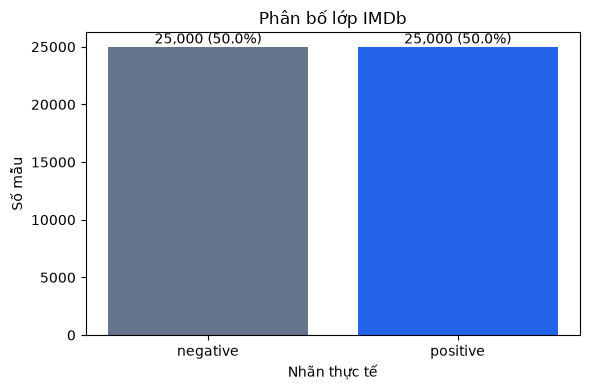

In [4]:
if deps["matplotlib"] is not None:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6,4))
    ordered = sorted(label_counts)
    ax.bar(ordered, [label_counts[x] for x in ordered], color=["#64748b","#2563eb"])
    ax.set(title="Phân bố lớp IMDb", xlabel="Nhãn thực tế", ylabel="Số mẫu")
    for i,name in enumerate(ordered): ax.text(i,label_counts[name],f"{label_counts[name]:,} ({100*label_counts[name]/len(labels):.1f}%)",ha="center",va="bottom")
    fig.tight_layout(); fig.savefig(ROOT/"class_distribution.png",dpi=160); plt.show()
else:
    try:
        from PIL import Image, ImageDraw
        canvas=Image.new("RGB",(640,420),"white"); draw=ImageDraw.Draw(canvas)
        draw.text((180,18),"IMDb sentiment class distribution",fill="#111827")
        draw.line((90,340,570,340),fill="#111827",width=2); draw.line((90,70,90,340),fill="#111827",width=2)
        colors={"negative":"#64748b","positive":"#2563eb"}
        for i,label in enumerate(sorted(label_counts)):
            x=190+i*210; height=int(220*label_counts[label]/max(label_counts.values()))
            draw.rectangle((x,340-height,x+100,340),fill=colors.get(label,"#2563eb"))
            draw.text((x,350),label,fill="#111827")
            draw.text((x,320-height),f"{label_counts[label]:,} ({class_distribution[label]['percent']:.1f}%)",fill="#111827")
        draw.text((12,72),"Samples",fill="#111827")
        canvas.save(ROOT/"class_distribution.png")
        print("Saved class_distribution.png using real dataset counts.")
    except ImportError:
        print("Class plot unavailable: matplotlib and Pillow are not installed; counts above are real.")

## 6. Giá trị thiếu và dữ liệu trùng lặp

In [5]:
missing_text_count = sum(1 for value in texts if not str(value).strip())
missing_label_count = sum(1 for value in labels if not str(value).strip())
exact_duplicate_count = len(texts)-len(set(texts))
duplicate_labels = defaultdict(set)
for text,label in zip(texts,labels): duplicate_labels[text].add(label)
conflicting_duplicate_texts = sum(1 for value in duplicate_labels.values() if len(value)>1)
print({"missing_texts":missing_text_count,"missing_labels":missing_label_count,"duplicate_rows_beyond_first":exact_duplicate_count,"unique_duplicate_texts":sum(1 for n in Counter(texts).values() if n>1),"duplicate_texts_with_conflicting_labels":conflicting_duplicate_texts})

{'missing_texts': 0, 'missing_labels': 0, 'duplicate_rows_beyond_first': 418, 'unique_duplicate_texts': 406, 'duplicate_texts_with_conflicting_labels': 0}


## 7. Chia tập dữ liệu và ngăn rò rỉ

In [6]:
# Exact duplicate texts stay in one split. StratifiedGroupKFold uses deterministic
# approximately 70/15/15 folds (14/3/3 of 20); fit estimators only on train.
splits = None
if deps["sklearn"] is not None:
    import numpy as np
    from sklearn.model_selection import StratifiedGroupKFold
    groups=np.asarray([hashlib.sha256(t.encode("utf-8")).hexdigest() for t in texts])
    folds=list(StratifiedGroupKFold(n_splits=20,shuffle=True,random_state=SEED).split(np.zeros(len(labels)),labels,groups))
    train_idx=np.concatenate([folds[i][1] for i in range(14)])
    val_idx=np.concatenate([folds[i][1] for i in range(14,17)])
    test_idx=np.concatenate([folds[i][1] for i in range(17,20)])
else:
    groups_to_rows=defaultdict(list)
    for i,text in enumerate(texts): groups_to_rows[text].append(i)
    totals=Counter(labels)
    ratios={"train":.70,"validation":.15,"test":.15}
    targets={name:{label:totals[label]*ratio for label in allowed_labels} for name,ratio in ratios.items()}
    current={name:Counter() for name in ratios}; bins={name:[] for name in ratios}
    ordered=sorted(groups_to_rows,key=lambda text:hashlib.sha256((str(SEED)+text).encode("utf-8")).hexdigest())
    for text in ordered:
        members=groups_to_rows[text]; counts=Counter(labels[i] for i in members)
        name=max(ratios,key=lambda s:sum(targets[s][label]-current[s][label] for label in counts))
        bins[name].extend(members); current[name].update(counts)
    train_idx,val_idx,test_idx=(bins[name] for name in ("train","validation","test"))
idx_sets={"train":set(map(int,train_idx)),"validation":set(map(int,val_idx)),"test":set(map(int,test_idx))}
assert not (idx_sets["train"]&idx_sets["validation"] or idx_sets["train"]&idx_sets["test"] or idx_sets["validation"]&idx_sets["test"])
text_sets={name:{texts[i] for i in indices} for name,indices in idx_sets.items()}
overlap={"train_validation":len(text_sets["train"]&text_sets["validation"]),"train_test":len(text_sets["train"]&text_sets["test"]),"validation_test":len(text_sets["validation"]&text_sets["test"])}
split_names={"train":train_idx,"validation":val_idx,"test":test_idx}
split_summary={name:{"samples":len(indices),"class_counts":dict(Counter(labels[int(i)] for i in indices))} for name,indices in split_names.items()}
print({"seed":SEED,"split_sizes":split_summary,"duplicate_text_overlap":overlap,"strategy":"StratifiedGroupKFold 14/3/3 of 20" if deps["sklearn"] is not None else "deterministic hash group stratification"})
if any(overlap.values()): raise AssertionError("Exact duplicate texts leaked across splits")
X_train,y_train=[texts[int(i)] for i in train_idx],[labels[int(i)] for i in train_idx]
X_val,y_val=[texts[int(i)] for i in val_idx],[labels[int(i)] for i in val_idx]
X_test,y_test=[texts[int(i)] for i in test_idx],[labels[int(i)] for i in test_idx]

{'seed': 42, 'split_sizes': {'train': {'samples': 35000, 'class_counts': {'positive': 17500, 'negative': 17500}}, 'validation': {'samples': 7500, 'class_counts': {'positive': 3750, 'negative': 3750}}, 'test': {'samples': 7500, 'class_counts': {'negative': 3750, 'positive': 3750}}}, 'duplicate_text_overlap': {'train_validation': 0, 'train_test': 0, 'validation_test': 0}, 'strategy': 'StratifiedGroupKFold 14/3/3 of 20'}


## Thí nghiệm 1 - Khảo sát tập dữ liệu

**Số liệu quan sát được:**

- 50,000 mẫu, 2 lớp: negative và positive đều 25.000 (50%). Tỷ lệ lớp lớn nhất/nhỏ nhất = 1; chênh lệch = 0 điểm phần trăm.
- Văn bản thiếu: 0; nhãn thiếu: 0; dòng trùng ngoài lần đầu: 418.
- Độ dài theo token khoảng trắng: trung bình 231.15694, trung vị 173.0, min=4, max=2470.
- train: 35,000 mẫu; phân bố nhãn {'positive': 17500, 'negative': 17500}.
- validation: 7,500 mẫu; phân bố nhãn {'positive': 3750, 'negative': 3750}.
- test: 7,500 mẫu; phân bố nhãn {'negative': 3750, 'positive': 3750}.
- Seed=42; trùng văn bản giữa các tập: {'train_validation': 0, 'train_test': 0, 'validation_test': 0}.

Lần chạy đầy đủ dùng StratifiedGroupKFold 14/3/3 trên 20 fold, giữ các review trùng trong cùng tập. Kích thước khác lần chỉ kiểm tra bằng phương pháp dự phòng trước đây. Không downsample.


**Bằng chứng:** Output khảo sát và split vừa chạy trên toàn bộ IMDb được cung cấp.

**Câu hỏi cho sinh viên:** Counts và tỷ lệ thực tế cho thấy mức mất cân bằng nào?

**Trả lời tham khảo (AI hỗ trợ, dựa trên kết quả thực nghiệm):**

Không có mất cân bằng lớp theo số lượng: negative và positive đều có 25.000 mẫu (50%); tỷ lệ lớp lớn nhất/nhỏ nhất bằng 1. Train có 17.500 mẫu mỗi lớp, validation và test có 3.750 mẫu mỗi lớp. Vì vậy không cần cân bằng lại chỉ vì tỷ lệ nhãn trong dữ liệu này. 418 dòng trùng là một vấn đề riêng; chúng được giữ trong cùng nhóm khi chia tập để tránh rò rỉ.


## 8. Mô hình cơ sở: TF-IDF + Logistic Regression

In [7]:
model_runs={}; result_records=[]
def add_record(experiment,model,representation,classifier,split,metric,value="",vocabulary_size="",training_time="",status="",input_text=""):
    result_records.append({"experiment":experiment,"model":model,"representation":representation,"classifier":classifier,"split":split,"metric":metric,"value":value,"vocabulary_size":vocabulary_size,"training_time":training_time,"status":status,"input_text":input_text})
def metric_values(y_true,y_pred):
    from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
    return {"accuracy":accuracy_score(y_true,y_pred),"precision":precision_score(y_true,y_pred,pos_label="positive",zero_division=0),"recall":recall_score(y_true,y_pred,pos_label="positive",zero_division=0),"f1":f1_score(y_true,y_pred,pos_label="positive",zero_division=0)}
def score_run(name,model,representation,classifier,vocabulary_size,elapsed):
    model_runs[name]={"model":model,"representation":representation,"classifier":classifier,"vocabulary_size":vocabulary_size,"training_time":elapsed}
    from sklearn.metrics import confusion_matrix
    for split,X,y in [("validation",X_val,y_val),("test",X_test,y_test)]:
        pred=model.predict(X); scores=metric_values(y,pred)
        for metric,value in scores.items(): add_record(name,name,representation,classifier,split,metric,value,vocabulary_size,elapsed,"completed")
        add_record(name,name,representation,classifier,split,"confusion_matrix",json.dumps(confusion_matrix(y,pred,labels=["negative","positive"]).tolist()),vocabulary_size,elapsed,"completed")
        model_runs[name][split]={"y":y,"pred":pred,"metrics":scores}
baseline=None
if deps["sklearn"] is not None:
    from sklearn.pipeline import Pipeline
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    baseline=Pipeline([("tfidf",TfidfVectorizer(tokenizer=tokenize_text,token_pattern=None,lowercase=False,ngram_range=(1,1),min_df=2,max_features=50000)),("classifier",LogisticRegression(max_iter=1000,random_state=SEED))])
    started=time.perf_counter(); baseline.fit(X_train,y_train); elapsed=time.perf_counter()-started
    vocab_size=len(baseline.named_steps["tfidf"].vocabulary_)
    score_run("tfidf_logistic_unigram",baseline,"TF-IDF unigram","LogisticRegression",vocab_size,elapsed)
    print({"training_seconds":elapsed,"vocabulary_size":vocab_size,"positive_label":"positive"})
else: print("SKIPPED: scikit-learn unavailable; no metrics are fabricated.")

{'training_seconds': 12.515985999954864, 'vocabulary_size': 50000, 'positive_label': 'positive'}


## Thí nghiệm 2 - TF-IDF + Logistic Regression

**Số liệu quan sát được:**

Vocabulary=50,000; thời gian fit=12.515986 giây. Lớp dương là positive.

| Tập | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| validation | 0.893600000 | 0.883177570 | 0.907200000 | 0.895027624 |
| test | 0.896400000 | 0.885803270 | 0.910133333 | 0.897803499 |

Confusion matrix test (hàng thực tế, cột dự đoán; negative, positive): `[[3310, 440], [337, 3413]]`.


**Bằng chứng:** Pipeline fit vocabulary trên train, validation/test chỉ transform. Không chọn siêu tham số từ test.

**Câu hỏi cho sinh viên:** Chỉ số nào phù hợp nhất với loại lỗi bạn cần ưu tiên?

**Trả lời tham khảo (AI hỗ trợ, dựa trên kết quả thực nghiệm):**

Trong lab này dùng F1 của lớp positive làm tiêu chí lựa chọn chính, đồng thời báo Accuracy và các chỉ số theo từng lớp. F1 xét đồng thời precision và recall: baseline có test F1=0.897803, precision=0.885803, recall=0.910133. Nếu cần ưu tiên tránh bỏ sót review positive thì tập trung vào Recall và FN; nếu cần tránh gán nhầm review negative thành positive thì tập trung vào Precision và FP. Đề không nêu chi phí lỗi cụ thể, nên chưa có cơ sở khẳng định một loại lỗi luôn quan trọng hơn. Ngưỡng quyết định, nếu điều chỉnh, phải chọn bằng validation.


## 9. Đánh giá mô hình cơ sở

In [8]:
if baseline is not None:
    from sklearn.metrics import classification_report
    print("Validation:",model_runs["tfidf_logistic_unigram"]["validation"]["metrics"])
    print("Test (predeclared config; not used for model selection):",model_runs["tfidf_logistic_unigram"]["test"]["metrics"])
    print(classification_report(y_test,baseline.predict(X_test),labels=["negative","positive"],zero_division=0))
    from IPython.display import display,Markdown
    m=model_runs["tfidf_logistic_unigram"]["validation"]["metrics"]
    display(Markdown(f"**Số liệu quan sát được:** validation accuracy={m['accuracy']:.4f}, precision={m['precision']:.4f}, recall={m['recall']:.4f}, F1={m['f1']:.4f}.\n\n**Bằng chứng:** cùng tập validation cố định; lớp dương là positive.\n\n**Câu hỏi cho sinh viên:** Chỉ số nào thể hiện chi phí bỏ sót review dương tính?"))
else: print("Metrics unavailable; baseline training skipped.")

Validation: {'accuracy': 0.8936, 'precision': 0.883177570093458, 'recall': 0.9072, 'f1': 0.8950276243093923}
Test (predeclared config; not used for model selection): {'accuracy': 0.8964, 'precision': 0.8858032701790812, 'recall': 0.9101333333333333, 'f1': 0.8978034986189662}


              precision    recall  f1-score   support

    negative       0.91      0.88      0.89      3750
    positive       0.89      0.91      0.90      3750

    accuracy                           0.90      7500
   macro avg       0.90      0.90      0.90      7500
weighted avg       0.90      0.90      0.90      7500



**Số liệu quan sát được:** validation accuracy=0.8936, precision=0.8832, recall=0.9072, F1=0.8950.

**Bằng chứng:** cùng tập validation cố định; lớp dương là positive.

**Câu hỏi cho sinh viên:** Chỉ số nào thể hiện chi phí bỏ sót review dương tính?

**Câu hỏi từ output:** Chỉ số nào thể hiện chi phí bỏ sót review dương tính?

**Trả lời tham khảo (AI hỗ trợ):** Recall của positive thể hiện tỷ lệ review positive được nhận diện đúng; FNR=1-Recall thể hiện tỷ lệ bỏ sót. Baseline có FN=337 trên 3750 review positive, FNR=0.089866667, Recall=0.910133333. Đây là số đếm/tỷ lệ lỗi; chi phí thực tế còn cần một giá trị chi phí cho mỗi FN do ứng dụng quy định.


## 10. Average Word2Vec + Logistic Regression

In [9]:
w2v_model=None; w2v_logistic=None; w2v_run=None
if deps["sklearn"] is not None and deps["gensim"] is not None:
    from gensim.models import Word2Vec
    from sklearn.linear_model import LogisticRegression
    train_tokens=[tokenize_text(text) for text in X_train]
    started=time.perf_counter()
    w2v_model=Word2Vec(sentences=train_tokens,vector_size=100,window=5,min_count=2,workers=1,sg=1,seed=SEED,epochs=10)
    def average_vectors(documents):
        vectors=[]
        for document in documents:
            available=[w2v_model.wv[token] for token in tokenize_text(document) if token in w2v_model.wv]
            vectors.append(np.mean(available,axis=0) if available else np.zeros(w2v_model.vector_size,dtype=np.float32))
        return np.asarray(vectors)
    V_train=average_vectors(X_train)
    w2v_logistic=LogisticRegression(max_iter=1000,random_state=SEED).fit(V_train,y_train)
    elapsed=time.perf_counter()-started
    class AverageWord2VecClassifier:
        def predict(self,docs): return w2v_logistic.predict(average_vectors(docs))
        def predict_proba(self,docs): return w2v_logistic.predict_proba(average_vectors(docs))
    w2v_run=AverageWord2VecClassifier()
    score_run("average_word2vec_logistic",w2v_run,"Average Word2Vec","LogisticRegression",len(w2v_model.wv),elapsed)
    print({"vector_size":100,"window":5,"min_count":2,"epochs":10,"seed":SEED,"architecture":"Skip-gram","training_texts":len(X_train),"vocabulary_size":len(w2v_model.wv)})
else: print("SKIPPED: requires scikit-learn and gensim; no metrics are fabricated.")

{'vector_size': 100, 'window': 5, 'min_count': 2, 'epochs': 10, 'seed': 42, 'architecture': 'Skip-gram', 'training_texts': 35000, 'vocabulary_size': 58892}


## Thí nghiệm 3 - Average Word2Vec + Logistic Regression

**Số liệu quan sát được:**

Vocabulary=58,892; thời gian train Word2Vec, tạo vector và fit LR=611.255613 giây.

| Tập | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| validation | 0.869733333 | 0.864197531 | 0.877333333 | 0.870715893 |
| test | 0.867733333 | 0.864814815 | 0.871733333 | 0.868260292 |

Skip-gram; vector_size=100, window=5, min_count=2, epochs=10, workers=1, seed=42. Chỉ train Word2Vec trên train; tài liệu không có token đã biết nhận vector 0.


**Bằng chứng:** Kết quả mới đo trên cùng split với TF-IDF.

**Câu hỏi cho sinh viên:** Những chênh lệch đo được hỗ trợ kết luận nào về hai biểu diễn?

**Trả lời tham khảo (AI hỗ trợ, dựa trên kết quả thực nghiệm):**

Với các cấu hình đã chạy, TF-IDF/LR tốt hơn Average Word2Vec/LR trên cùng split: validation F1 cao hơn 2.431173 điểm phần trăm; test F1 cao hơn 2.954321 điểm phần trăm và test Accuracy cao hơn 2.866667 điểm phần trăm. Thời gian fit đo được là 12.516s so với 611.256s, tức Word2Vec/LR khoảng 48.84 lần; thời gian Word2Vec gồm học embedding, tạo vector tài liệu và fit LR. Có thể ưu tiên TF-IDF/LR trong phép so sánh này. Chưa thể kết luận mọi Word2Vec đều kém TF-IDF hoặc khẳng định nguyên nhân ngữ nghĩa từ các metric đơn lẻ.


## 11. So sánh biểu diễn

In [10]:
comparison=[{"model":name,"representation":run["representation"],"classifier":run["classifier"],"validation":run.get("validation",{}).get("metrics"),"test":run.get("test",{}).get("metrics"),"training_time_seconds":run["training_time"],"vocabulary_size":run["vocabulary_size"]} for name,run in model_runs.items()]
print(json.dumps(comparison,indent=2))
if w2v_run is not None:
    from IPython.display import display,Markdown
    m=model_runs["average_word2vec_logistic"]["validation"]["metrics"]
    display(Markdown(f"**Số liệu quan sát được:** validation accuracy={m['accuracy']:.4f}, precision={m['precision']:.4f}, recall={m['recall']:.4f}, F1={m['f1']:.4f}.\n\n**Bằng chứng:** Word2Vec chỉ học trên train, dùng cùng tập validation.\n\n**Câu hỏi cho sinh viên:** Biểu diễn nào có kết quả validation tốt hơn theo các số đo này?"))

[
  {
    "model": "tfidf_logistic_unigram",
    "representation": "TF-IDF unigram",
    "classifier": "LogisticRegression",
    "validation": {
      "accuracy": 0.8936,
      "precision": 0.883177570093458,
      "recall": 0.9072,
      "f1": 0.8950276243093923
    },
    "test": {
      "accuracy": 0.8964,
      "precision": 0.8858032701790812,
      "recall": 0.9101333333333333,
      "f1": 0.8978034986189662
    },
    "training_time_seconds": 12.515985999954864,
    "vocabulary_size": 50000
  },
  {
    "model": "average_word2vec_logistic",
    "representation": "Average Word2Vec",
    "classifier": "LogisticRegression",
    "validation": {
      "accuracy": 0.8697333333333334,
      "precision": 0.8641975308641975,
      "recall": 0.8773333333333333,
      "f1": 0.8707158925499537
    },
    "test": {
      "accuracy": 0.8677333333333334,
      "precision": 0.8648148148148148,
      "recall": 0.8717333333333334,
      "f1": 0.8682602921646746
    },
    "training_time_seconds": 

**Số liệu quan sát được:** validation accuracy=0.8697, precision=0.8642, recall=0.8773, F1=0.8707.

**Bằng chứng:** Word2Vec chỉ học trên train, dùng cùng tập validation.

**Câu hỏi cho sinh viên:** Biểu diễn nào có kết quả validation tốt hơn theo các số đo này?

**Câu hỏi từ output:** Biểu diễn nào có kết quả validation tốt hơn theo các số đo này?

**Trả lời tham khảo (AI hỗ trợ):** Trong hai model ở output này, TF-IDF/LR có validation Accuracy=0.893600000, F1=0.895027624; Average Word2Vec/LR có Accuracy=0.869733333, F1=0.870715893. TF-IDF/LR cao hơn ở cả Accuracy, Precision, Recall và F1; chênh lệch F1=2.431173 điểm phần trăm. Kết luận chỉ áp dụng cho cấu hình và split đã chạy; chưa xác định nguyên nhân ngữ nghĩa.


## Thí nghiệm 3 - So sánh biểu diễn và classifier

**Số liệu quan sát được:**

| Mô hình | Tập | Accuracy | Precision | Recall | F1 |
|---|---|---:|---:|---:|---:|
| TF-IDF/LR | validation | 0.893600000 | 0.883177570 | 0.907200000 | 0.895027624 |
| TF-IDF/LR | test | 0.896400000 | 0.885803270 | 0.910133333 | 0.897803499 |
| Average Word2Vec/LR | validation | 0.869733333 | 0.864197531 | 0.877333333 | 0.870715893 |
| Average Word2Vec/LR | test | 0.867733333 | 0.864814815 | 0.871733333 | 0.868260292 |
| TF-IDF/Linear SVM | validation | 0.898400000 | 0.892331933 | 0.906133333 | 0.899179677 |
| TF-IDF/Linear SVM | test | 0.896000000 | 0.889355008 | 0.904533333 | 0.896879958 |

Chênh lệch Word2Vec/LR - TF-IDF/LR (validation): accuracy=-0.023866667; precision=-0.018980039; recall=-0.029866667; f1=-0.024311732.

Chênh lệch Word2Vec/LR - TF-IDF/LR (test): accuracy=-0.028666667; precision=-0.020988455; recall=-0.038400000; f1=-0.029543206.

Chênh lệch Linear SVM - TF-IDF/LR (validation): accuracy=+0.004800000; precision=+0.009154363; recall=-0.001066667; f1=+0.004152053.

Chênh lệch Linear SVM - TF-IDF/LR (test): accuracy=-0.000400000; precision=+0.003551738; recall=-0.005600000; f1=-0.000923541.

Cấu hình có validation F1 cao nhất trong bốn cấu hình định trước: `tfidf_logistic_unigram_bigram`. Không suy ra nguyên nhân ngữ nghĩa từ các điểm số này.


**Bằng chứng:** Cùng train/validation/test; cấu hình đã xác định trước khi đọc test metrics.

**Câu hỏi cho sinh viên:** Chênh lệch validation có đủ để quyết định cho nhiệm vụ của bạn không?

**Trả lời tham khảo (AI hỗ trợ, dựa trên kết quả thực nghiệm):**

Đủ để chọn một cấu hình tạm thời trong phạm vi lab, nhưng chưa đủ để kết luận ưu thế ổn định ngoài split này. Unigram+bigram/LR có validation F1=0.907964, cao nhất trong bốn cấu hình; hơn unigram/LR 1.293651 điểm phần trăm và hơn Linear SVM 0.878446 điểm phần trăm. Vì tiêu chí đã định là validation F1, chọn cấu hình này trước khi diễn giải test. Muốn kết luận chắc hơn cần đánh giá độ biến thiên qua nhiều seed hoặc các fold giữ nhóm review trùng, cùng ngân sách feature và khoảng tin cậy. Lần chạy hiện tại không cung cấp các phép đo bất định đó.


## 12. Linear SVM tùy chọn

In [11]:
svm_model=None
if deps["sklearn"] is not None:
    from sklearn.pipeline import Pipeline
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.svm import LinearSVC
    svm_model=Pipeline([("tfidf",TfidfVectorizer(tokenizer=tokenize_text,token_pattern=None,lowercase=False,ngram_range=(1,1),min_df=2,max_features=50000)),("classifier",LinearSVC(random_state=SEED))])
    started=time.perf_counter(); svm_model.fit(X_train,y_train); elapsed=time.perf_counter()-started
    score_run("tfidf_linear_svm_unigram",svm_model,"TF-IDF unigram","LinearSVC",len(svm_model.named_steps["tfidf"].vocabulary_),elapsed)
    print("Validation:",model_runs["tfidf_linear_svm_unigram"]["validation"]["metrics"],"Test:",model_runs["tfidf_linear_svm_unigram"]["test"]["metrics"])
else: print("SKIPPED: scikit-learn unavailable.")
comparison=[{"model":name,"representation":run["representation"],"classifier":run["classifier"],"validation":run["validation"]["metrics"],"test":run["test"]["metrics"],"training_seconds":run["training_time"],"vocabulary_size":run["vocabulary_size"]} for name,run in model_runs.items()]
print("So sánh đủ TF-IDF/LR, Word2Vec/LR, Linear SVM:",json.dumps(comparison,ensure_ascii=False,indent=2))


Validation: {'accuracy': 0.8984, 'precision': 0.8923319327731093, 'recall': 0.9061333333333333, 'f1': 0.8991796771632707} Test: {'accuracy': 0.896, 'precision': 0.8893550078657577, 'recall': 0.9045333333333333, 'f1': 0.8968799576943416}
So sánh đủ TF-IDF/LR, Word2Vec/LR, Linear SVM: [
  {
    "model": "tfidf_logistic_unigram",
    "representation": "TF-IDF unigram",
    "classifier": "LogisticRegression",
    "validation": {
      "accuracy": 0.8936,
      "precision": 0.883177570093458,
      "recall": 0.9072,
      "f1": 0.8950276243093923
    },
    "test": {
      "accuracy": 0.8964,
      "precision": 0.8858032701790812,
      "recall": 0.9101333333333333,
      "f1": 0.8978034986189662
    },
    "training_seconds": 12.515985999954864,
    "vocabulary_size": 50000
  },
  {
    "model": "average_word2vec_logistic",
    "representation": "Average Word2Vec",
    "classifier": "LogisticRegression",
    "validation": {
      "accuracy": 0.8697333333333334,
      "precision": 0.8641975

### Kết quả Linear SVM

**Số liệu quan sát được:**

Vocabulary=50,000; thời gian fit=13.328219 giây.

| Tập | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| validation | 0.898400000 | 0.892331933 | 0.906133333 | 0.899179677 |
| test | 0.896000000 | 0.889355008 | 0.904533333 | 0.896879958 |


**Bằng chứng:** Linear SVM đã chạy, không bị bỏ qua. Vectorizer chỉ fit trên train.

**Câu hỏi cho sinh viên:** Bạn đánh giá sự khác biệt với LR thế nào theo metric đo được?

**Trả lời tham khảo (AI hỗ trợ, dựa trên kết quả thực nghiệm):**

Linear SVM có validation F1 cao hơn unigram/LR 0.415205 điểm phần trăm. Trên test, SVM có precision cao hơn 0.355174 điểm phần trăm nhưng recall thấp hơn 0.560000 điểm phần trăm; Accuracy thấp hơn 0.040000 điểm phần trăm và F1 thấp hơn 0.092354 điểm phần trăm. Như vậy không có một classifier vượt trội ở mọi chỉ số. Chênh lệch F1 nhỏ trên một split chưa chứng minh khác biệt có ý nghĩa thống kê; không đổi lựa chọn mô hình chỉ vì nhìn thấy test.


## 13. Thí nghiệm về thứ tự từ

In [12]:
s1,s2="this movie is good","this movie is not good"
word_order_rows=[]
if baseline is not None:
    vectorizer=baseline.named_steps["tfidf"]
    for phrase in [s1,s2]:
        row=vectorizer.transform([phrase])
        features=[(vectorizer.get_feature_names_out()[i],float(row[0,i])) for i in row.indices]
        probabilities=dict(zip(baseline.classes_,map(float,baseline.predict_proba([phrase])[0])))
        predicted=baseline.predict([phrase])[0]
        word_order_rows.append({"representation":"TF-IDF unigram","text":phrase,"tokens":tokenize_text(phrase),"tfidf_features":features,"oov_tokens":[t for t in tokenize_text(phrase) if t not in vectorizer.vocabulary_],"prediction":str(predicted),"probabilities":probabilities})
        print({"text":phrase,"tokens":tokenize_text(phrase),"token_count":len(tokenize_text(phrase)),"tfidf_features":features,"predicted_class":predicted,"probabilities":probabilities})
        add_record("word_order_demo","tfidf_logistic_unigram","TF-IDF unigram","LogisticRegression","demo","token_count",len(tokenize_text(phrase)),len(vectorizer.vocabulary_),status="observed",input_text=phrase)
        add_record("word_order_demo","tfidf_logistic_unigram","TF-IDF unigram","LogisticRegression","demo","predicted_class",predicted,len(vectorizer.vocabulary_),status="observed",input_text=phrase)
        add_record("word_order_demo","tfidf_logistic_unigram","TF-IDF unigram","LogisticRegression","demo","predicted_probability_positive",probabilities.get("positive",""),len(vectorizer.vocabulary_),status="observed",input_text=phrase)
        for feature,value in features:
            add_record("word_order_demo","tfidf_logistic_unigram","TF-IDF unigram","LogisticRegression","demo",f"tfidf_feature:{feature}",value,len(vectorizer.vocabulary_),status="observed",input_text=phrase)
else: print("TF-IDF demo scores and classes unavailable until dependencies are installed.")
if w2v_model is not None:
    v1,v2=average_vectors([s1,s2]); denom=float(np.linalg.norm(v1)*np.linalg.norm(v2))
    cosine=float(np.dot(v1,v2)/denom) if denom else 0.0
    def oov_count(text):
        tokens=tokenize_text(text); return {"tokens":len(tokens),"oov":sum(token not in w2v_model.wv for token in tokens)}
    print({"average_vector_cosine_similarity":cosine,"S1":oov_count(s1),"S2":oov_count(s2),"note":"Average includes not but does not model word order/compositional scope."})
    add_record("word_order_demo","average_word2vec_logistic","Average Word2Vec","LogisticRegression","demo","cosine_similarity",cosine,len(w2v_model.wv),status="observed",input_text=s1+" | "+s2)
    for phrase in [s1,s2]:
        counts=oov_count(phrase)
        probabilities=dict(zip(w2v_logistic.classes_,map(float,w2v_run.predict_proba([phrase])[0])))
        vector=average_vectors([phrase])[0]
        entry={"representation":"Average Word2Vec","text":phrase,"tokens":tokenize_text(phrase),"token_count":counts["tokens"],"oov_tokens":[t for t in tokenize_text(phrase) if t not in w2v_model.wv],"averaged_vector":vector.tolist(),"vector_l2_norm":float(np.linalg.norm(vector)),"cosine_S1_S2":cosine,"prediction":str(w2v_run.predict([phrase])[0]),"probabilities":probabilities}
        word_order_rows.append(entry)
        print(json.dumps(entry,ensure_ascii=False,indent=2))
        add_record("word_order_demo","average_word2vec_logistic","Average Word2Vec","LogisticRegression","demo","predicted_probability_positive",probabilities["positive"],len(w2v_model.wv),status="observed",input_text=phrase)
        add_record("word_order_demo","average_word2vec_logistic","Average Word2Vec","LogisticRegression","demo",f"token_count:{phrase}",counts["tokens"],len(w2v_model.wv),status="observed",input_text=phrase)
        add_record("word_order_demo","average_word2vec_logistic","Average Word2Vec","LogisticRegression","demo",f"oov_count:{phrase}",counts["oov"],len(w2v_model.wv),status="observed",input_text=phrase)
else: print("Word2Vec demo unavailable until dependencies are installed.")
(ROOT/"word_order_demo.json").write_text(json.dumps(word_order_rows,ensure_ascii=False,indent=2),encoding="utf-8")


{'text': 'this movie is good', 'tokens': ['this', 'movie', 'is', 'good'], 'token_count': 4, 'tfidf_features': [('good', 0.6736598134815897), ('is', 0.37992479458383965), ('movie', 0.511002065298024), ('this', 0.37512197405848013)], 'predicted_class': np.str_('positive'), 'probabilities': {np.str_('negative'): 0.19598781387897657, np.str_('positive'): 0.8040121861210234}}


{'text': 'this movie is not good', 'tokens': ['this', 'movie', 'is', 'not', 'good'], 'token_count': 5, 'tfidf_features': [('good', 0.5978680987144163), ('is', 0.33718044337301556), ('movie', 0.45351055103009924), ('not', 0.46082196855725377), ('this', 0.33291797570239245)], 'predicted_class': np.str_('positive'), 'probabilities': {np.str_('negative'): 0.4900264471702105, np.str_('positive'): 0.5099735528297895}}
{'average_vector_cosine_similarity': 0.9766854643821716, 'S1': {'tokens': 4, 'oov': 0}, 'S2': {'tokens': 5, 'oov': 0}, 'note': 'Average includes not but does not model word order/compositional scope.'}
{
  "representation": "Average Word2Vec",
  "text": "this movie is good",
  "tokens": [
    "this",
    "movie",
    "is",
    "good"
  ],
  "token_count": 4,
  "oov_tokens": [],
  "averaged_vector": [
    0.22794951498508453,
    0.1382277011871338,
    0.20428386330604553,
    -0.06102187931537628,
    -0.24248751997947693,
    0.11871457099914551,
    -0.09511251002550125,
   

7642

## Thí nghiệm 4 - Thứ tự từ và phủ định

**Số liệu quan sát được:**

| Câu | Biểu diễn | Token | OOV | Dự đoán | P(positive) |
|---|---|---:|---:|---|---:|
| `this movie is good` | TF-IDF unigram | 4 | 0 | positive | 0.804012186 |
| `this movie is not good` | TF-IDF unigram | 5 | 0 | positive | 0.509973553 |
| `this movie is good` | Average Word2Vec | 4 | 0 | positive | 0.743084669 |
| `this movie is not good` | Average Word2Vec | 5 | 0 | negative | 0.249183640 |

TF-IDF `this movie is good`: `[['good', 0.6736598134815897], ['is', 0.37992479458383965], ['movie', 0.511002065298024], ['this', 0.37512197405848013]]`.

TF-IDF `this movie is not good`: `[['good', 0.5978680987144163], ['is', 0.33718044337301556], ['movie', 0.45351055103009924], ['not', 0.46082196855725377], ['this', 0.33291797570239245]]`.

Vector trung bình `this movie is good`: 8 tọa độ đầu `[0.22794951498508453, 0.1382277011871338, 0.20428386330604553, -0.06102187931537628, -0.24248751997947693, 0.11871457099914551, -0.09511251002550125, 0.1370212733745575]`; chuẩn L2=1.866264343; toàn bộ 100 tọa độ có trong output và word_order_demo.json.

Vector trung bình `this movie is not good`: 8 tọa độ đầu `[0.2248244285583496, 0.10993138700723648, 0.17550548911094666, -0.09557580947875977, -0.2758823037147522, 0.11587953567504883, -0.09890465438365936, 0.06676135957241058]`; chuẩn L2=1.834463239; toàn bộ 100 tọa độ có trong output và word_order_demo.json.

Cosine giữa hai vector trung bình: **0.976685464382**. OOV từng câu được liệt kê trong JSON. Hai câu chỉ là minh họa, không phải evaluation định lượng; average không trực tiếp mô hình hóa thứ tự hoặc phạm vi phủ định.


**Bằng chứng:** TF-IDF features, vector và xác suất được tính từ các model vừa train.

**Câu hỏi cho sinh viên:** Kết quả này cho biết gì về token not, và điều gì về composition vẫn chưa được kiểm tra?

**Trả lời tham khảo (AI hỗ trợ, dựa trên kết quả thực nghiệm):**

Cả hai câu đều không có OOV. Thêm `not` làm thay đổi TF-IDF: xuất hiện trọng số `not`=0,460821969 và các trọng số cũ thay đổi do L2-normalization. P(positive) của TF-IDF/LR giảm từ 0.804012186 xuống 0.509973553, nhưng vẫn nhỉnh hơn ngưỡng 0,5 nên cả hai bị dự đoán positive. Average Word2Vec tạo hai vector khác nhau, cosine=0.976685464382; P(positive) giảm từ 0.743084669 xuống 0.249183640, nên dự đoán chuyển từ positive sang negative.

Điều được kiểm chứng là tác động của việc thêm token `not` trong hai câu này. Hai câu không chỉ khác thứ tự mà còn khác tập token, nên phép thử không tách riêng hiệu ứng word order. Với cùng tập token và số lần xuất hiện, TF-IDF unigram và phép lấy trung bình vector đều bất biến với hoán vị. Kết quả đúng của Word2Vec ở đây chưa chứng minh nó hiểu phủ định, phạm vi của phủ định hoặc composition nói chung; cần thêm các cặp câu kiểm soát và tập đánh giá lớn hơn.


## 14. Unigram và unigram + bigram

In [13]:
bigram_model=None
if deps["sklearn"] is not None:
    bigram_model=Pipeline([("tfidf",TfidfVectorizer(tokenizer=tokenize_text,token_pattern=None,lowercase=False,ngram_range=(1,2),min_df=2,max_features=100000)),("classifier",LogisticRegression(max_iter=1000,random_state=SEED))])
    started=time.perf_counter(); bigram_model.fit(X_train,y_train); elapsed=time.perf_counter()-started
    score_run("tfidf_logistic_unigram_bigram",bigram_model,"TF-IDF unigram+bigram","LogisticRegression",len(bigram_model.named_steps["tfidf"].vocabulary_),elapsed)
    names=set(bigram_model.named_steps["tfidf"].get_feature_names_out())
    print({"vocabulary_size":len(names),"training_seconds":elapsed,"candidate_features":{f:f in names for f in ["not good","very good"]},"validation":model_runs["tfidf_logistic_unigram_bigram"]["validation"]["metrics"],"test":model_runs["tfidf_logistic_unigram_bigram"]["test"]["metrics"]})
else: print("SKIPPED: sklearn unavailable; no unigram/bigram metrics.")

{'vocabulary_size': 100000, 'training_seconds': 40.423605200019665, 'candidate_features': {'not good': True, 'very good': True}, 'validation': {'accuracy': 0.9069333333333334, 'precision': 0.8980177360459051, 'recall': 0.9181333333333334, 'f1': 0.9079641350210971}, 'test': {'accuracy': 0.9070666666666667, 'precision': 0.8980443285528031, 'recall': 0.9184, 'f1': 0.9081081081081082}}


## Thí nghiệm 5 - Unigram và unigram + bigram

**Số liệu quan sát được:**

| Cấu hình | Vocabulary | Thời gian fit (s) | F1 validation | F1 test |
|---|---:|---:|---:|---:|
| Unigram | 50,000 | 12.515986 | 0.895027624 | 0.897803499 |
| Unigram + bigram | 100,000 | 40.423605 | 0.907964135 | 0.908108108 |

Chênh lệch bigram - unigram: vocabulary=+50000; thời gian=+27.907619s; F1 validation=+0.012936511; F1 test=+0.010304609.

Feature có thật và coefficient: `{'not good': -1.1059921847827268, 'very good': 1.7498258978386758}`.

Cùng split và Logistic Regression. Cấu hình đã định trước dùng max_features=50.000 ở unigram và 100.000 ở bigram; khác biệt cap cũng ảnh hưởng phép so sánh, nên không quy toàn bộ chênh lệch cho n-gram.


**Bằng chứng:** Các feature và hệ số lấy từ vocabulary thật, không ghi cứng.

**Câu hỏi cho sinh viên:** Số liệu có hỗ trợ sử dụng cấu hình bigram này không?

**Trả lời tham khảo (AI hỗ trợ, dựa trên kết quả thực nghiệm):**

Có, trong phạm vi cấu hình và tiêu chí validation đang dùng: F1 validation tăng 1.293651 điểm phần trăm; test F1 tăng 1.030461 điểm phần trăm. Đổi lại vocabulary tăng từ 50.000 lên 100.000 và thời gian fit tăng từ 12.516s lên 40.424s, khoảng 3.23 lần. Các feature `not good` và `very good` tồn tại thật, có coefficient lần lượt -1.105992 và 1.749826.

Có thể dùng cấu hình unigram+bigram/LR nếu ưu tiên F1 và chấp nhận chi phí này. Tuy nhiên max_features cũng đổi từ 50.000 sang 100.000, nên thí nghiệm không chứng minh toàn bộ mức tăng đến riêng từ bigram. Cần cùng cap hoặc cùng ngân sách feature để tách riêng hiệu ứng; không kết luận bigram luôn cải thiện.


## 15. Ma trận nhầm lẫn

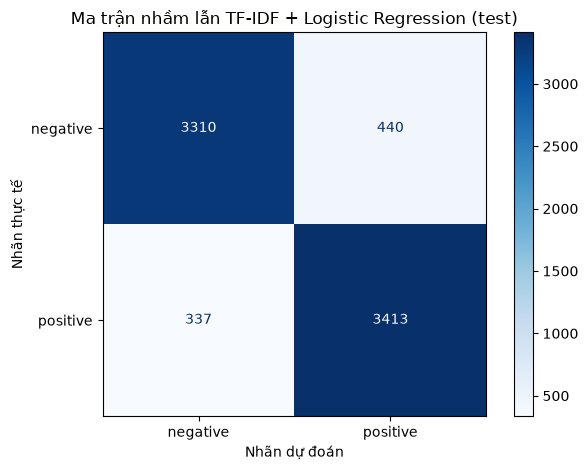

Rows=actual, columns=predicted; labels=['negative','positive']; saved: D:\Study\Semester 7\NLP\Lab04\confusion_matrix.png
Ma trận (hàng thực tế, cột dự đoán): [[3310, 440], [337, 3413]]


In [14]:
if baseline is not None:
    from sklearn.metrics import confusion_matrix
    cm=confusion_matrix(y_test,baseline.predict(X_test),labels=["negative","positive"])
    if deps["matplotlib"] is not None:
        from sklearn.metrics import ConfusionMatrixDisplay
        import matplotlib.pyplot as plt
        ConfusionMatrixDisplay(cm,display_labels=["negative","positive"]).plot(cmap="Blues",values_format="d")
        plt.title("Ma trận nhầm lẫn TF-IDF + Logistic Regression (test)")
        plt.gca().set_xlabel("Nhãn dự đoán"); plt.gca().set_ylabel("Nhãn thực tế")
        plt.tight_layout(); plt.savefig(CONFUSION_PATH,dpi=160); plt.show()
    else:
        try:
            from PIL import Image, ImageDraw
            canvas=Image.new("RGB",(640,420),"white"); draw=ImageDraw.Draw(canvas)
            draw.text((220,18),"Confusion matrix - test set",fill="#111827")
            draw.text((275,70),"Predicted",fill="#111827")
            draw.text((195,105),"negative",fill="#111827"); draw.text((365,105),"positive",fill="#111827")
            draw.text((72,170),"Actual",fill="#111827"); draw.text((100,185),"negative",fill="#111827"); draw.text((100,275),"positive",fill="#111827")
            for r in range(2):
                for col in range(2):
                    x=260+col*115; y=145+r*90
                    draw.rectangle((x,y,x+95,y+72),fill="#dbeafe",outline="#334155",width=2)
                    draw.text((x+38,y+28),str(int(cm[r,col])),fill="#111827")
            canvas.save(CONFUSION_PATH)
        except ImportError:
            print("Confusion matrix counts:",cm.tolist(),"(Pillow is required to save the PNG.)")
    print("Rows=actual, columns=predicted; labels=['negative','positive']; saved:",CONFUSION_PATH)
else:
    try:
        from PIL import Image, ImageDraw
        canvas=Image.new("RGB",(640,320),"white"); draw=ImageDraw.Draw(canvas)
        draw.text((250,70),"NOT RUN",fill="#b91c1c")
        draw.text((105,125),"No confusion matrix: model dependencies are unavailable.",fill="#111827")
        draw.text((105,160),"No model predictions or counts have been fabricated.",fill="#111827")
        canvas.save(CONFUSION_PATH)
        print("Saved status card, not a confusion matrix; no model was trained.")
    except ImportError:
        print("Confusion matrix unavailable: no trained classifier and no Pillow for status image.")

print("Ma trận (hàng thực tế, cột dự đoán):",cm.tolist())


## Đánh giá - Ma trận nhầm lẫn và chỉ số theo lớp

**Số liệu quan sát được:**

Ma trận test: `[[3310, 440], [337, 3413]]`. Hàng là nhãn thực tế, cột là nhãn dự đoán; thứ tự negative, positive. TN=3310, FP=440, FN=337, TP=3413.

| Lớp | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| negative | 0.907595284 | 0.882666667 | 0.894957415 | 3750 |
| positive | 0.885803270 | 0.910133333 | 0.897803499 | 3750 |

![Ma trận nhầm lẫn](confusion_matrix.png)


**Bằng chứng:** Ma trận và classification_report lấy từ dự đoán test mới của baseline.

**Câu hỏi cho sinh viên:** FP và FN phản ánh loại lỗi nào, và loại nào quan trọng hơn đối với ứng dụng?

**Trả lời tham khảo (AI hỗ trợ, dựa trên kết quả thực nghiệm):**

Với positive là lớp dương, FP=440 là review negative bị gán positive; FN=337 là review positive bị gán negative. FP chiếm 11.733333% trong 3.750 review negative, FN chiếm 8.986667% trong 3.750 review positive. Tổng số lỗi là 777, tương ứng 10.36% test. Mô hình có nhiều FP hơn FN trong lần chạy này.

Nếu hệ thống dùng để tránh quảng bá phim bị đánh giá kém, FP có thể tốn kém hơn; nếu dùng để tìm các review tích cực mà không bỏ sót, FN có thể quan trọng hơn. Đây là các tình huống giả định; đề chưa quy định ứng dụng và chi phí lỗi, nên chỉ từ confusion matrix không thể quyết định loại nào quan trọng hơn. Cần xác định chi phí rồi chọn ngưỡng trên validation.


## 16. Ví dụ phân loại đúng và sai

In [15]:
error_examples=[]
if baseline is not None:
    pred=baseline.predict(X_test); prob=baseline.predict_proba(X_test)
    correct=[i for i,(a,b) in enumerate(zip(y_test,pred)) if a==b][:3]
    incorrect=[i for i,(a,b) in enumerate(zip(y_test,pred)) if a!=b][:3]
    def make_examples(indices,kind):
        output=[]; clf=baseline.named_steps["classifier"]; vec=baseline.named_steps["tfidf"]; feature_names=vec.get_feature_names_out()
        for i in indices:
            row=vec.transform([X_test[i]]); signed=clf.coef_[0] if pred[i]=="positive" else -clf.coef_[0]
            support=sorted([(feature_names[j],float(signed[j]*row[0,j])) for j in row.indices],key=lambda x:x[1],reverse=True)[:5]
            output.append({"kind":kind,"text":X_test[i],"text_preview":X_test[i][:500],"true_label":y_test[i],"predicted_label":pred[i],"confidence":float(max(prob[i])),"predicted_scores":dict(zip(baseline.classes_,map(float,prob[i]))),"supporting_features":support})
        return output
    error_examples=make_examples(correct,"correct")+make_examples(incorrect,"incorrect")
    print(json.dumps(error_examples,indent=2,ensure_ascii=False))
else: print("Examples unavailable until classifier training succeeds.")
assert sum(e["kind"]=="correct" for e in error_examples)>=3
assert sum(e["kind"]=="incorrect" for e in error_examples)>=3
(ROOT/"error_examples.json").write_text(json.dumps(error_examples,ensure_ascii=False,indent=2),encoding="utf-8")


[
  {
    "kind": "correct",
    "text": "So im not a big fan of Boll's work but then again not many are. I enjoyed his movie Postal (maybe im the only one). Boll apparently bought the rights to use Far Cry long ago even before the game itself was even finsished. <br /><br />People who have enjoyed killing mercs and infiltrating secret research labs located on a tropical island should be warned, that this is not Far Cry... This is something Mr Boll have schemed together along with his legion of schmucks.. Feeling loneley on the set Mr Boll invites three of his countrymen to play with. These players go by the names of Til Schweiger, Udo Kier and Ralf Moeller.<br /><br />Three names that actually have made them selfs pretty big in the movie biz. So the tale goes like this, Jack Carver played by Til Schweiger (yes Carver is German all hail the bratwurst eating dudes!!) However I find that Tils acting in this movie is pretty badass.. People have complained about how he's not really staying

14895

## Bằng chứng cho phân tích lỗi

**Số liệu quan sát được:** 3 review đúng và 3 review sai lấy từ test. Full text, xác suất từng lớp và feature hỗ trợ có trong error_examples.json.

### Ví dụ 1: đúng

Nhãn thật=negative; dự đoán=negative; confidence=0.821256848; xác suất={'negative': 0.8212568482023185, 'positive': 0.17874315179768155}.

> So im not a big fan of Boll's work but then again not many are. I enjoyed his movie Postal (maybe im the only one). Boll apparently bought the rights to use Far Cry long ago even before the game itself was even finsished. <br /><br />People who have enjoyed killing mercs and infiltrating secret research labs located on a tropical island should be warned, that this is not Far Cry... This is something Mr Boll have schemed together along with his legion of schmucks.. Feeling loneley on the set Mr B

Đóng góp feature hỗ trợ: `[['boll', 0.2679840257181983], ['far', 0.22986305000985094], ['even', 0.19417868308166072], ['not', 0.1770308278902922], ['annoying', 0.1553458142436731]]`.

### Ví dụ 2: đúng

Nhãn thật=negative; dự đoán=negative; confidence=0.993977239; xác suất={'negative': 0.9939772394684268, 'positive': 0.006022760531573297}.

> I had the terrible misfortune of having to view this "b-movie" in it's entirety.<br /><br />All I have to say is--- save your time and money!!! This has got to be the worst b-movie of all time, it shouldn't even be called a b-movie, more like an f-movie! Because it fails in all aspects that make a good movie: the story is not interesting at all, all of the actors are paper-thin and not at all believable, it has bad direction and the action sequences are so fake it's almost funny.......almost.<br

Đóng góp feature hỗ trợ: `[['worst', 0.6889360594257635], ['terrible', 0.4635215955230832], ['bad', 0.40725430508165306], ['fails', 0.4022276634641927], ['horrible', 0.3631351037156434]]`.

### Ví dụ 3: đúng

Nhãn thật=negative; dự đoán=negative; confidence=0.858248826; xác suất={'negative': 0.858248825626068, 'positive': 0.141751174373932}.

> I'm not sure why the producers needed to trade on the name of a somewhat successful movie franchise because the title suggests that it is a sequel to the first three movies..which it is not. Even though Marques Houston did appear in "HP3", he played a totally different character (he was, eight years older) in this film. Okay...so Reid and Martin weren't the most talented and couldn't carry a film all by themselves..but to trade on the HP franchise seems to me that there could have made some sort

Đóng góp feature hỗ trợ: `[['not', 0.38965674190193667], ['sorry', 0.2298550746254249], ['franchise', 0.20757120746933075], ['sequel', 0.17920179754006302], ["couldn't", 0.17834610684489235]]`.

### Ví dụ 4: sai

Nhãn thật=positive; dự đoán=negative; confidence=0.610842833; xác suất={'negative': 0.6108428328101966, 'positive': 0.3891571671898034}.

> The three main characters are all hopeless, and yet you only feel sorry for one of them: Ernesto, hopelessly devoted to Mercedes. This was part of the frustration: screaming at Mercedes to get a clue and ditch the no-good Harry, to no avail.<br /><br />Then there's the satisfaction: Steve Buscemi has a great part as a transvestite, and Harvey Keitel's moving story of his indignity playing a gorilla for a cheap TV movie is incredible. When you least expect it, Quentin Tarintino is doing half a mo

Đóng góp feature hỗ trợ: `[['no', 0.5035343174278584], ['cheap', 0.286379340701008], ['sorry', 0.2626432581929623], ['wonder', 0.2167375915560654], ['half', 0.20455128606640283]]`.

### Ví dụ 5: sai

Nhãn thật=positive; dự đoán=negative; confidence=0.705467451; xác suất={'negative': 0.7054674511527941, 'positive': 0.29453254884720587}.

> This is an OK adaptation of the breath taking book of Dan Brown. I can't say it is novel or very good but they made a movie that you can enjoy. Given the excellent story, the result could have been better though. The movie is pretty long but at the end I was feeling like some things were missing. Sound effects and sound tracks were very good. Acting was well done but the character development phase was very weak. For people who didn't read the book, things may look happening too quickly. From my

Đóng góp feature hỗ trợ: `[['book', 0.5598741849057098], ['weak', 0.3039180259034124], ['instead', 0.28257982001592036], ['could', 0.25143171340061526], ['was', 0.22444713700762917]]`.

### Ví dụ 6: sai

Nhãn thật=positive; dự đoán=negative; confidence=0.725158565; xác suất={'negative': 0.7251585646680533, 'positive': 0.2748414353319467}.

> A fey story of a Martian attempt to colonize Earth. (Things must be pretty bad back on Mars.) Two state troopers investigate the scene of a reported UFO crash. Whatever landed is buried under the ice at Tracy's Pond but there are footsteps in the snow leading to a nearby diner.<br /><br />The diner has had no customers since eleven o'clock that morning. Now there are a handful of bus passengers sitting around waiting for permission to cross a structurally weak bridge. The bus driver insists that

Đóng góp feature hỗ trợ: `[['no', 0.27828966097287045], ['bad', 0.22199981004146566], ['weak', 0.15624759603847785], ['attempt', 0.13350233635159406], ['to', 0.11695703647892634]]`.


**Bằng chứng:** Văn bản và score đều từ lần dự đoán test mới; diễn giải tham khảo chỉ dựa trên bằng chứng trong review.

**Câu hỏi cho sinh viên:** Bằng chứng trong review hỗ trợ cách giải thích của bạn thế nào?

**Trả lời tham khảo (AI hỗ trợ, dựa trên kết quả thực nghiệm):**

Các đóng góp dưới đây là các hạng tuyến tính theo hướng nhãn được dự đoán, chưa bao gồm toàn bộ feature và intercept. Chúng hỗ trợ giải thích một phần score, không chứng minh một nguyên nhân duy nhất.

1. **Ví dụ đúng 1:** review có các nhận xét như “the storyline ... beyond demented”, “most of it will suck” và “very annoying sidekick”, phù hợp nhãn negative. `annoying` đóng góp 0,155346 vào hướng negative; `boll` và `far` cũng có đóng góp lớn nhưng là tên/ngữ cảnh, không phải bản thân chúng có nghĩa tiêu cực. P(negative)=0,821257.
2. **Ví dụ đúng 2:** người viết trực tiếp dùng “worst b-movie”, “terrible”, “bad direction” và “fails”. Các contribution `worst`=0,688936, `terrible`=0,463522, `bad`=0,407254 phù hợp với lời chê; P(negative)=0,993977.
3. **Ví dụ đúng 3:** kết luận “THUMBS DOWN” và nhận xét “not funny” cho thấy thái độ negative. Các từ `not`, `sorry`, `franchise`, `sequel` góp theo hướng negative; P(negative)=0,858249. Không phải mọi feature này đều mang nghĩa sentiment độc lập.
4. **Ví dụ sai 4:** nhãn positive, kết luận “no wonder I liked it”, nhưng `no` góp 0,503534, `cheap` góp 0,286379 và `sorry` góp 0,262643 theo hướng negative. `no` trong cụm “no wonder” không phủ định việc thích phim; `cheap TV movie` nằm trong câu kể về nhân vật. Đây là bằng chứng rằng các unigram được cộng riêng có thể không phản ánh đúng chức năng của cụm hoặc đối tượng được đánh giá. P(negative)=0,610843; cần ablation theo cụm/ngữ cảnh để xác minh đầy đủ giả thuyết này.
5. **Ví dụ sai 5:** review pha trộn lời khen và chê; có “very weak”, “could have been better” nhưng cũng có “worth watching”. Nhãn là positive, trong khi `book` góp 0,559874 và `weak` góp 0,303918 theo hướng negative; P(negative)=0,705467. `book` ở đây là tín hiệu thống kê đã học, không tự mang sentiment negative. Cách biểu diễn cộng unigram không phân biệt trực tiếp kết luận tổng thể với từng lời phê bình.
6. **Ví dụ sai 6:** “bad back on Mars” và “structurally weak bridge” mô tả nội dung cốt truyện; người viết đánh giá “thoroughly enjoyable” và “I always enjoy it”. Tuy vậy `no`=0,278290, `bad`=0,222000, `weak`=0,156248 góp về negative; P(negative)=0,725159. Bằng chứng gợi ý cần phân biệt mô tả tình tiết với thái độ đối với phim, nhưng chưa đủ để khẳng định đây là toàn bộ nguyên nhân lỗi.

Cả ba ví dụ sai được chọn đều là FN; cách lấy ba lỗi đầu tiên không đại diện cho tất cả 777 lỗi hoặc cho FP. Không có bằng chứng ở đây để tự gán sarcasm, domain bias hoặc lỗi nhãn.


## 17. Kiểm tra trọng số mô hình

In [16]:
weight_examples={}
if baseline is not None:
    vectorizer=baseline.named_steps["tfidf"]; clf=baseline.named_steps["classifier"]
    names=vectorizer.get_feature_names_out(); coef=clf.coef_[0]
    pos_order=np.argsort(coef)[-20:][::-1]; neg_order=np.argsort(coef)[:20]
    weight_examples={"label_mapping":label_mapping,"classes":list(clf.classes_),"highest_positive":[(names[i],float(coef[i])) for i in pos_order],"most_negative":[(names[i],float(coef[i])) for i in neg_order],"requested_features":{f:float(coef[list(names).index(f)]) if f in names else None for f in ["good","bad","excellent","terrible","not good"]}}
    print(json.dumps(weight_examples,indent=2))
else: print("Model coefficients unavailable until baseline training succeeds.")
weight_examples["bigram_features"]={term:float(bigram_model.named_steps["classifier"].coef_[0][bigram_model.named_steps["tfidf"].vocabulary_[term]]) for term in ["not good","very good"] if term in bigram_model.named_steps["tfidf"].vocabulary_}
print("Hệ số bigram có thật:",weight_examples["bigram_features"])
(ROOT/"model_weights.json").write_text(json.dumps(weight_examples,ensure_ascii=False,indent=2),encoding="utf-8")


{
  "label_mapping": {
    "negative": 0,
    "positive": 1
  },
  "classes": [
    "negative",
    "positive"
  ],
  "highest_positive": [
    [
      "great",
      8.923027790727097
    ],
    [
      "excellent",
      7.031771211867654
    ],
    [
      "7",
      5.933094009669933
    ],
    [
      "best",
      5.640698237479344
    ],
    [
      "perfect",
      4.86893310883196
    ],
    [
      "wonderful",
      4.812894156700426
    ],
    [
      "amazing",
      4.5553567210547365
    ],
    [
      "8",
      4.424239558513576
    ],
    [
      "fun",
      4.2843438485480005
    ],
    [
      "highly",
      4.165098895107641
    ],
    [
      "loved",
      4.160127850930879
    ],
    [
      "favorite",
      4.158019376191622
    ],
    [
      "brilliant",
      4.139672283670333
    ],
    [
      "enjoyed",
      4.1003266020010125
    ],
    [
      "hilarious",
      4.056461098676522
    ],
    [
      "well",
      4.045224342740269
    ],
    [
      

2604

## Khả năng diễn giải mô hình - Hệ số feature

**Số liệu quan sát được:** ánh xạ negative=0, positive=1; classes của LR là `[negative, positive]`. Coefficient dương hướng về positive, âm hướng về negative.

### 20 hệ số dương lớn nhất

| Feature | Coefficient |
|---|---:|
| `great` | 8.923027790727 |
| `excellent` | 7.031771211868 |
| `7` | 5.933094009670 |
| `best` | 5.640698237479 |
| `perfect` | 4.868933108832 |
| `wonderful` | 4.812894156700 |
| `amazing` | 4.555356721055 |
| `8` | 4.424239558514 |
| `fun` | 4.284343848548 |
| `highly` | 4.165098895108 |
| `loved` | 4.160127850931 |
| `favorite` | 4.158019376192 |
| `brilliant` | 4.139672283670 |
| `enjoyed` | 4.100326602001 |
| `hilarious` | 4.056461098677 |
| `well` | 4.045224342740 |
| `today` | 3.985276155483 |
| `fantastic` | 3.925698966235 |
| `love` | 3.909688370608 |
| `superb` | 3.861843032717 |

### 20 hệ số âm nhỏ nhất

| Feature | Coefficient |
|---|---:|
| `worst` | -10.711144623128 |
| `bad` | -8.825485057833 |
| `awful` | -7.568967410442 |
| `waste` | -7.433956995685 |
| `boring` | -6.890276237500 |
| `poor` | -6.274108022661 |
| `terrible` | -6.273196047247 |
| `nothing` | -5.489417348664 |
| `dull` | -5.098786711058 |
| `worse` | -4.968730893721 |
| `poorly` | -4.726845075717 |
| `horrible` | -4.627804919228 |
| `disappointing` | -4.449473063642 |
| `fails` | -4.429438896234 |
| `unfortunately` | -4.414404352003 |
| `minutes` | -4.395458256552 |
| `stupid` | -4.322894479945 |
| `no` | -4.257926044512 |
| `supposed` | -4.103529167250 |
| `script` | -4.093714190326 |

Các term cần kiểm tra (None nghĩa là không thuộc vocabulary unigram): `{'good': 2.485262721165155, 'bad': -8.825485057832509, 'excellent': 7.031771211867654, 'terrible': -6.273196047247195, 'not good': None}`. Hệ số bigram: `{'not good': -1.1059921847827268, 'very good': 1.7498258978386758}`. Giá trị đầy đủ trong model_weights.json.


**Bằng chứng:** Trích trực tiếp feature names và coef_ của model đã fit.

**Câu hỏi cho sinh viên:** Các coefficient đo được hỗ trợ diễn giải nào, và giới hạn của cách diễn giải đó là gì?

**Trả lời tham khảo (AI hỗ trợ, dựa trên kết quả thực nghiệm):**

Trong LR binary, log-odds positive là intercept cộng tổng `coefficient × TF-IDF`. Hệ số dương làm tăng hướng positive, hệ số âm làm giảm hướng positive khi giữ các feature khác cố định. Ví dụ `great`=8.923028, `excellent`=7.031771 hướng positive; `worst`=-10.711145, `bad`=-8.825485, `terrible`=-6.273196 hướng negative. `good` có hệ số 2.485263; `not good` không thuộc unigram vocabulary, nhưng có hệ số -1.105992 trong model bigram.

Hệ số là liên hệ thống kê trong tập train, không phải ý nghĩa cố định của từ hoặc quan hệ nhân quả. Đóng góp trong một review còn phụ thuộc giá trị TF-IDF, các feature khác và intercept; coefficient lớn không tự quyết định nhãn. Unigram không xác định trực tiếp phạm vi phủ định hoặc từ đang mô tả nhân vật/cốt truyện hay ý kiến về phim. Các hệ số từ hai model có vocabulary/ngữ cảnh feature khác nhau cũng không nên so sánh như một thước đo nghĩa tuyệt đối.


## 18. Xuất tệp results.csv

In [17]:
add_record("dataset_inspection","IMDb supplied archive","raw text","none","all","samples",len(rows),status="observed")
add_record("dataset_inspection","IMDb supplied archive","raw text","none","all","missing_texts",missing_text_count,status="observed")
add_record("dataset_inspection","IMDb supplied archive","raw text","none","all","missing_labels",missing_label_count,status="observed")
add_record("dataset_inspection","IMDb supplied archive","raw text","none","all","duplicate_rows_beyond_first",exact_duplicate_count,status="observed")
for label,info in class_distribution.items():
    add_record("dataset_inspection","IMDb supplied archive","raw text","none","all",f"class_count:{label}",info["count"],status="observed")
    add_record("dataset_inspection","IMDb supplied archive","raw text","none","all",f"class_percent:{label}",info["percent"],status="observed")
for name,info in split_summary.items():
    add_record("split","IMDb supplied archive","raw text","none",name,"samples",info["samples"],status="observed")
    for label,count in info["class_counts"].items(): add_record("split","IMDb supplied archive","raw text","none",name,f"class_count:{label}",count,status="observed")
for run_name,exp,model,rep,clf in [
    ("tfidf_logistic_unigram","baseline","TF-IDF + Logistic Regression","TF-IDF unigram","LogisticRegression"),
    ("average_word2vec_logistic","representation","Average Word2Vec + Logistic Regression","Average Word2Vec","LogisticRegression"),
    ("tfidf_linear_svm_unigram","optional","TF-IDF + Linear SVM","TF-IDF unigram","LinearSVC"),
    ("tfidf_logistic_unigram_bigram","ngram","Unigram vs bigram","TF-IDF unigram+bigram","LogisticRegression")]:
    if run_name not in model_runs:
        for split in ["validation","test"]:
            add_record(exp,model,rep,clf,split,"f1",status="BLOCKED_MISSING_DEPENDENCIES")
if baseline is None:
    for phrase in ["this movie is good","this movie is not good"]:
        add_record("word_order_demo","tfidf_logistic_unigram","TF-IDF unigram","LogisticRegression","demo",f"prediction:{phrase}",status="BLOCKED_MISSING_DEPENDENCIES")
if w2v_model is None:
    add_record("word_order_demo","average_word2vec_logistic","Average Word2Vec","LogisticRegression","demo","cosine_similarity",status="BLOCKED_MISSING_DEPENDENCIES")
required_runs={"tfidf_logistic_unigram","average_word2vec_logistic","tfidf_linear_svm_unigram","tfidf_logistic_unigram_bigram"}
assert required_runs.issubset(model_runs), "Thiếu thí nghiệm bắt buộc"
assert not any(r["status"].startswith("BLOCKED") for r in result_records)
fields=["experiment","model","representation","classifier","split","metric","value","vocabulary_size","training_time","status","input_text"]
with RESULTS_PATH.open("w",newline="",encoding="utf-8") as f:
    writer=csv.DictWriter(f,fieldnames=fields); writer.writeheader(); writer.writerows(result_records)
print(f"Saved {len(result_records)} records to {RESULTS_PATH}")
from sklearn.metrics import classification_report
run_summary={"dataset":"IMDb supplied local archive","archive_sha256":hashlib.sha256(DATA_ZIP.read_bytes()).hexdigest(),"seed":SEED,"versions":versions,"samples":len(rows),"class_distribution":class_distribution,"length_statistics":length_stats,"missing_texts":missing_text_count,"missing_labels":missing_label_count,"duplicates":exact_duplicate_count,"split_summary":split_summary,"duplicate_overlap":overlap,"models":{name:{"representation":run["representation"],"classifier":run["classifier"],"training_seconds":run["training_time"],"vocabulary_size":run["vocabulary_size"],"validation":run["validation"]["metrics"],"test":run["test"]["metrics"]} for name,run in model_runs.items()},"baseline_confusion_matrix":cm.tolist(),"baseline_classification_report":classification_report(y_test,baseline.predict(X_test),labels=["negative","positive"],output_dict=True,zero_division=0),"validation_selection":max(model_runs,key=lambda name:model_runs[name]["validation"]["metrics"]["f1"]),"word_order":word_order_rows,"model_weights":weight_examples,"error_examples":error_examples,"tests_passed":unit_result.testsRun}
(ROOT/"run_summary.json").write_text(json.dumps(run_summary,ensure_ascii=False,indent=2),encoding="utf-8")
print("Đã xuất đủ 4 cấu hình; không có thí nghiệm bị bỏ qua.")


Saved 79 records to D:\Study\Semester 7\NLP\Lab04\results.csv


Đã xuất đủ 4 cấu hình; không có thí nghiệm bị bỏ qua.
